# Schott--Stommel beta spiral

This notebook reproduces the local planetary-geostrophic mechanism and absolute-velocity inversion developed by Schott and Stommel (1978), *Beta spirals and absolute velocities in different oceans* ([doi:10.1016/0011-7471(78)90001-7](https://doi.org/10.1016/0011-7471(78)90001-7)). It is a synthetic, nondimensional water-column experiment rather than a full basin solve: the assumptions in the paper are steady geostrophy, negligible relative vorticity, adiabatic motion, and a linear beta plane.

The example shows three linked ideas:

1. downwelling turns the horizontal velocity clockwise with increasing depth in the Northern Hemisphere;
2. isopycnal slopes encode the turning through thermal wind and potential-vorticity conservation; and
3. observations at many depths determine the unknown reference velocity by an overdetermined least-squares fit.

In [1]:
using Pkg
Pkg.activate(joinpath(@__DIR__, "..", "PlanetaryGeostrophy"))
using PlanetaryGeostrophy
using LinearAlgebra
using Random
using Statistics
using Plots

default(; linewidth=2, framestyle=:box, legend=:best)

  Activating project at `~/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy`


## Local PG column

Let $z$ increase upward, write $(u,v)=V(\cos\theta,\sin\theta)$, and take density to increase downward, so $\rho_z<0$. Schott and Stommel combine steady density conservation, thermal wind, and linear potential-vorticity conservation:

$$u\rho_x+v\rho_y+w\rho_z=0,\qquad u_z=\gamma\rho_y,\qquad v_z=-\gamma\rho_x,\qquad w_z=\frac{\beta}{f}v.$$

For constant speed $V$, no local heating, and uniform $\rho_z$, these reduce to

$$\theta_z=\frac{\rho_z}{\gamma V^2}w,\qquad w_z=\frac{\beta}{f}V\sin\theta.$$

The constant-speed choice closes this pedagogical column without adding dynamics not present in the paper. Starting with $w=0$ at the base and an equatorward component ($v<0$), the beta constraint generates downwelling above. Because $\rho_z<0$, the velocity angle increases upward and therefore turns clockwise when followed downward.

In [2]:
H = 1.0
Nz = 101
z = collect(range(-H, 0.0; length=Nz))
speed = 1.0
gamma = 1.0
rho_z = -1.0
beta_over_f = 2.0
theta_bottom = -0.8
w_bottom = 0.0

rhs(theta, w) = (
    rho_z * w / (gamma * speed^2),
    beta_over_f * speed * sin(theta),
)

function integrate_column(z, theta0, w0)
    theta = similar(z)
    w = similar(z)
    theta[1], w[1] = theta0, w0
    for k in 1:(length(z) - 1)
        dz = z[k + 1] - z[k]
        k1 = rhs(theta[k], w[k])
        k2 = rhs(theta[k] + dz * k1[1] / 2, w[k] + dz * k1[2] / 2)
        k3 = rhs(theta[k] + dz * k2[1] / 2, w[k] + dz * k2[2] / 2)
        k4 = rhs(theta[k] + dz * k3[1], w[k] + dz * k3[2])
        theta[k + 1] = theta[k] + dz * (k1[1] + 2k2[1] + 2k3[1] + k4[1]) / 6
        w[k + 1] = w[k] + dz * (k1[2] + 2k2[2] + 2k3[2] + k4[2]) / 6
    end
    return theta, w
end

theta, w = integrate_column(z, theta_bottom, w_bottom)
u = speed .* cos.(theta)
v = speed .* sin.(theta)

101-element Vector{Float64}:
 -0.7173560908995228
 -0.7173061109540522
 -0.7171561559381835
 -0.7169061803464405
 -0.7165561084462643
 -0.7161058344428126
 -0.7155552227095733
 -0.7149041080846842
 -0.7141522962328208
 -0.7132995640724799
  ⋮
 -0.2532535200379571
 -0.2431493386031095
 -0.23297141297513768
 -0.22272248134682116
 -0.21240534700333816
 -0.2020228762599458
 -0.19157799627772507
 -0.18107369276072988
 -0.17051300753821824

## The spiral

The hodograph connects velocity vectors from the bottom (dark) to the top (light). Reading it from the surface downward, the vector turns clockwise, the Northern Hemisphere subtropical sense identified in the paper. This is a geostrophic beta spiral, not an Ekman spiral: vertical shear follows the horizontal density gradient rather than a local stress balance.

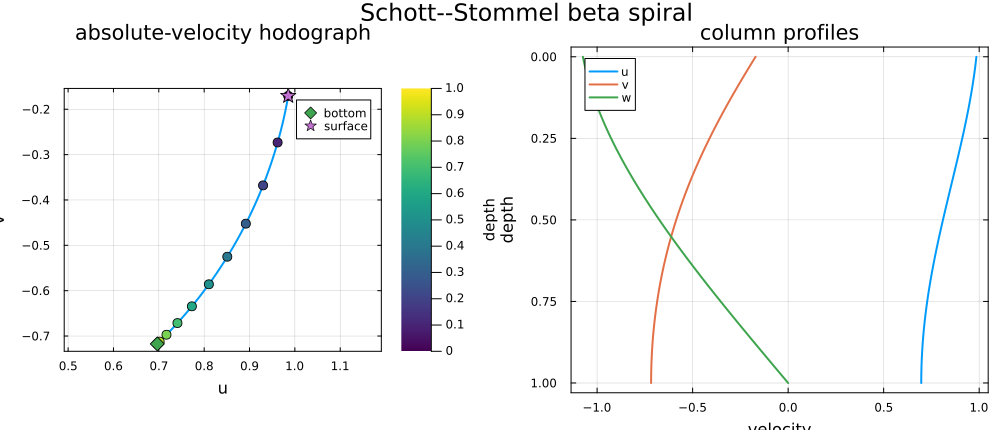

In [3]:
depth = -z
levels = 1:10:Nz
hodograph = plot(
    u, v;
    xlabel="u", ylabel="v", aspect_ratio=:equal,
    title="absolute-velocity hodograph", label=false,
)
scatter!(
    hodograph, u[levels], v[levels];
    marker_z=depth[levels], color=:viridis, colorbar_title="depth",
    markersize=5, label=false,
)
scatter!(hodograph, [u[1]], [v[1]]; marker=:diamond, markersize=7, label="bottom")
scatter!(hodograph, [u[end]], [v[end]]; marker=:star5, markersize=8, label="surface")

profiles = plot(u, depth; xlabel="velocity", ylabel="depth", yflip=true, label="u")
plot!(profiles, v, depth; label="v")
plot!(profiles, w, depth; label="w")
plot!(profiles; title="column profiles")

spiral_figure = plot(
    hodograph, profiles;
    layout=(1, 2), size=(1000, 430),
    plot_title="Schott--Stommel beta spiral",
)
savefig(spiral_figure, joinpath(@__DIR__, "pg_beta_spiral.png"))
display(spiral_figure)

## Isopycnal slopes and the beta constraint

For an isopycnal height $h(x,y)$, thermal wind gives

$$h_x=\frac{v_z}{\gamma\rho_z},\qquad h_y=-\frac{u_z}{\gamma\rho_z}.$$

Differentiating density conservation and substituting $w_z=(\beta/f)v$ yields equation (1.6) of Schott and Stommel:

$$u h_{xz}+v\left(h_{yz}-\frac{\beta}{f}\right)=0.$$

The following cell evaluates the slopes and their vertical derivatives analytically from the integrated column. It also verifies both $w=u h_x+v h_y$ and the beta constraint.

In [4]:
theta_z = rho_z .* w ./ (gamma * speed^2)
theta_zz = rho_z .* beta_over_f .* v ./ (gamma * speed^2)
u_z = -speed .* sin.(theta) .* theta_z
v_z = speed .* cos.(theta) .* theta_z
u_zz = -speed .* (cos.(theta) .* theta_z.^2 .+ sin.(theta) .* theta_zz)
v_zz = speed .* (-sin.(theta) .* theta_z.^2 .+ cos.(theta) .* theta_zz)

h_x = v_z ./ (gamma * rho_z)
h_y = -u_z ./ (gamma * rho_z)
h_xz = v_zz ./ (gamma * rho_z)
h_yz = -u_zz ./ (gamma * rho_z)

w_from_slopes = u .* h_x .+ v .* h_y
beta_residual = u .* h_xz .+ v .* (h_yz .- beta_over_f)
constraint_check = (
    maximum_vertical_velocity_error=maximum(abs, w_from_slopes .- w),
    maximum_beta_constraint_residual=maximum(abs, beta_residual),
)
display(constraint_check)

(maximum_vertical_velocity_error = 2.220446049250313e-16, maximum_beta_constraint_residual = 3.3306690738754696e-16)

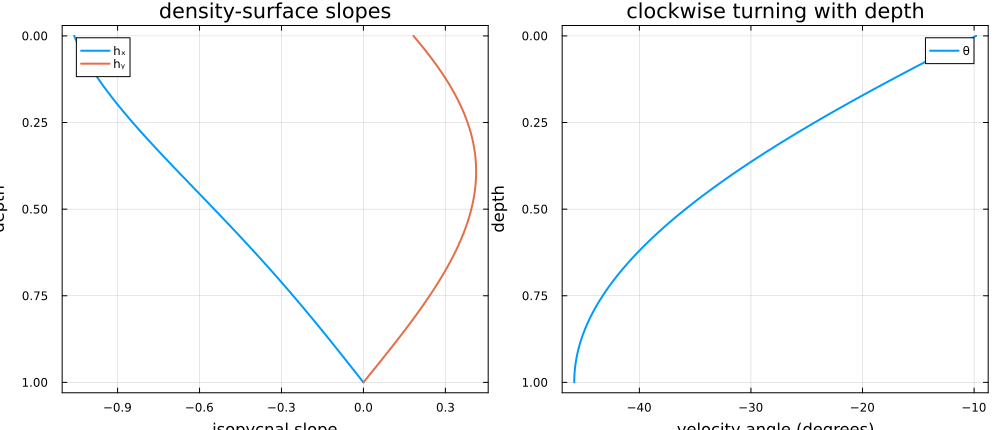

In [5]:
slope_panel = plot(h_x, depth; xlabel="isopycnal slope", ylabel="depth", yflip=true, label="hₓ")
plot!(slope_panel, h_y, depth; label="hᵧ", title="density-surface slopes")

turning_panel = plot(rad2deg.(theta), depth;
    xlabel="velocity angle (degrees)", ylabel="depth", yflip=true,
    label="θ", title="clockwise turning with depth")

slope_figure = plot(slope_panel, turning_panel; layout=(1, 2), size=(1000, 430))
savefig(slope_figure, joinpath(@__DIR__, "pg_beta_spiral_slopes.png"))
display(slope_figure)

## Recovering absolute velocity

Hydrography determines vertical shear, so suppose the measured current is relative to the bottom level: $u=u_0+u'$ and $v=v_0+v'$. At every sampled depth, equation (1.7) gives

$$u_0 h_{xz}+v_0\left(h_{yz}-\frac{\beta}{f}\right)=-u'h_{xz}-v'\left(h_{yz}-\frac{\beta}{f}\right).$$

Stacking the equations produces the modestly overdetermined system $A\boldsymbol{u}_0=\boldsymbol{c}$. The exact synthetic observations recover the reference velocity without imposing a level of no motion.

In [6]:
reference_index = 1
u_relative = u .- u[reference_index]
v_relative = v .- v[reference_index]

function reference_velocity(u_relative, v_relative, h_xz, h_yz, q)
    A = hcat(h_xz, h_yz .- q)
    c = .-(u_relative .* h_xz .+ v_relative .* (h_yz .- q))
    estimate = A \ c
    residual = A * estimate - c
    return (; estimate, residual, A, c)
end

exact_fit = reference_velocity(u_relative, v_relative, h_xz, h_yz, beta_over_f)
u_recovered = u_relative .+ exact_fit.estimate[1]
v_recovered = v_relative .+ exact_fit.estimate[2]

display((
    true_reference=(u[reference_index], v[reference_index]),
    recovered_reference=Tuple(exact_fit.estimate),
    rms_residual=sqrt(mean(abs2, exact_fit.residual)),
))

(true_reference = (0.6967067093471654, -0.7173560908995228), recovered_reference = (0.6967067093471647, -0.7173560908995232), rms_residual = 1.5424973443730015e-15)

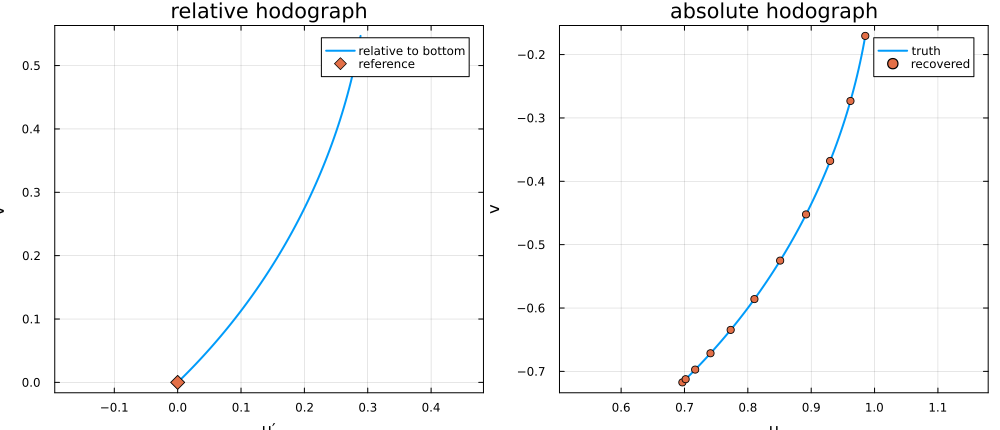

In [7]:
relative_panel = plot(
    u_relative, v_relative;
    xlabel="u′", ylabel="v′", aspect_ratio=:equal,
    title="relative hodograph", label="relative to bottom",
)
scatter!(relative_panel, [0.0], [0.0]; marker=:diamond, markersize=7, label="reference")

absolute_panel = plot(
    u, v;
    xlabel="u", ylabel="v", aspect_ratio=:equal,
    title="absolute hodograph", label="truth",
)
scatter!(absolute_panel, u_recovered[levels], v_recovered[levels];
    marker=:circle, markersize=4, label="recovered")

inversion_figure = plot(relative_panel, absolute_panel; layout=(1, 2), size=(1000, 430))
savefig(inversion_figure, joinpath(@__DIR__, "pg_beta_spiral_inversion.png"))
display(inversion_figure)

## Noisy observations and the wrong-latitude test

Schott and Stommel judged whether beta genuinely constrained the fit by repeating the inversion with deliberately wrong values of $\beta/f$. A credible data set should have a residual minimum near the true latitude. Here small, reproducible perturbations mimic uncertainty in relative velocity and slope derivatives. The recovered offset remains close to the truth, and the residual ratio $R/C$ selects the correct beta parameter.

In [8]:
rng = MersenneTwister(1978)
noise_fraction = 0.015
perturb(values) = values .+ noise_fraction * max(std(values), eps()) .* randn(rng, length(values))

u_relative_observed = perturb(u_relative)
v_relative_observed = perturb(v_relative)
h_xz_observed = perturb(h_xz)
h_yz_observed = perturb(h_yz)

noisy_fit = reference_velocity(
    u_relative_observed, v_relative_observed,
    h_xz_observed, h_yz_observed, beta_over_f,
)

q_trials = range(0.25beta_over_f, 1.75beta_over_f; length=121)
quality = map(q_trials) do q
    fit = reference_velocity(
        u_relative_observed, v_relative_observed,
        h_xz_observed, h_yz_observed, q,
    )
    sum(abs2, fit.residual) / sum(abs2, fit.c)
end
best_q = q_trials[argmin(quality)]

display((
    true_reference=(u[reference_index], v[reference_index]),
    noisy_recovery=Tuple(noisy_fit.estimate),
    true_beta_over_f=beta_over_f,
    residual_minimum=best_q,
))

(true_reference = (0.6967067093471654, -0.7173560908995228), noisy_recovery = (0.6972280517476921, -0.7178457204948453), true_beta_over_f = 2.0, residual_minimum = 2.0)

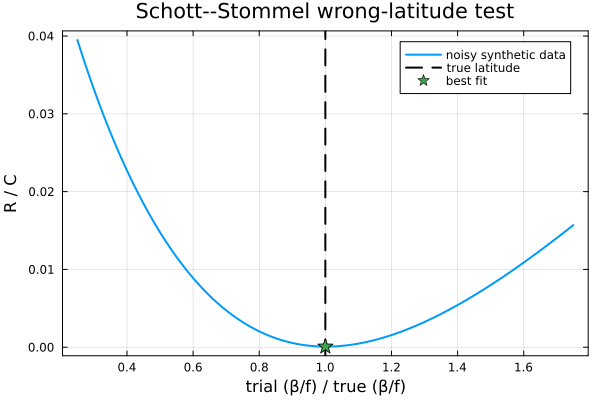

In [9]:
wrong_latitude_figure = plot(
    q_trials ./ beta_over_f, quality;
    xlabel="trial (β/f) / true (β/f)", ylabel="R / C",
    title="Schott--Stommel wrong-latitude test", label="noisy synthetic data",
)
vline!(wrong_latitude_figure, [1.0]; linestyle=:dash, color=:black, label="true latitude")
scatter!(wrong_latitude_figure, [best_q / beta_over_f], [minimum(quality)];
    marker=:star5, markersize=8, label="best fit")
savefig(wrong_latitude_figure, joinpath(@__DIR__, "pg_beta_spiral_wrong_latitude.png"))
display(wrong_latitude_figure)

## Comparison with the robust-diagnostic PG model

The repository's PG solver is *robust diagnostic*: the buoyancy field is relaxed towards a prescribed field $B$ and is not advected. The adiabatic constraint (1.6) that generates the Schott--Stommel spiral is therefore absent, and the PG model cannot produce a spiral on its own. In a closed basin with forcing that varies smoothly in the horizontal, for example, the depth-integrated flow is weak and the interior velocity simply reverses with depth.

What the PG model can do is diagnose the velocity implied by a given density field. Here the inviscid column's density structure is imposed on a closed, flat-bottom $\beta$-plane basin. The restoring field is a stable stratification $N^2 z$ plus horizontal gradients whose thermal wind, $f\,\partial_z u=-\partial_y b$ and $f\,\partial_z v=\partial_x b$, equals the column's shear scaled by an amplitude $a$. Choosing $N^2 = a f_0 \gamma (-\rho_z)$ makes the PG isopycnal slopes equal to the column's. Strong restoring ($\Gamma = 2$) keeps $b \approx B$ outside thin boundary layers, and a weak subtropical wind stress drives a Sverdrup circulation. A small Ekman number, $\mathrm{Ek} = 5\times10^{-4}$, makes the Ekman depth $\sqrt{2\mathrm{Ek}} \approx 0.03H$ small compared with the $0.15H$ margins that exclude the boundary layers from the interior comparison. At $\mathrm{Ek} = 0.004$ the Ekman spiral reaches the reference level and the relative-shear mismatch is about 20%.

Two questions follow. Does the PG model reproduce the spiral's relative (thermal-wind) hodograph? And what sets its absolute reference velocity?

In [ ]:
# Thermal-wind shear of the inviscid column at any depth (piecewise linear).
function column_interpolant(values)
    return zz -> begin
        k = clamp(searchsortedlast(z, zz), 1, length(z) - 1)
        s = (zz - z[k]) / (z[k + 1] - z[k])
        (1 - s) * values[k] + s * values[k + 1]
    end
end
u_z_at = column_interpolant(u_z)
v_z_at = column_interpolant(v_z)

pg_Lx, pg_Ly, pg_H = 2.0, 1.2, H
pg_f0, pg_beta = 1.0, 0.35
pg_Ek, pg_Gamma = 0.0005, 2.0
pg_tau0 = 4e-4
pg_amplitude = 0.02
pg_N2 = pg_amplitude * pg_f0 * gamma * (-rho_z)

pg_eta(y) = (y + pg_Ly / 2) / pg_Ly
pg_tau_x(x, y) = -pg_tau0 * cos(pi * pg_eta(y))
pg_wind_curl(x, y) = -pg_tau0 * pi / pg_Ly * sin(pi * pg_eta(y))
pg_restoring_buoyancy(x, y, zz) =
    pg_N2 * zz + pg_amplitude * pg_f0 * (x * v_z_at(zz) - y * u_z_at(zz))
pg_surface_buoyancy(x, y) = pg_restoring_buoyancy(x, y, 0.0)

pg_problem = PGProblem(
    parameters=PGParameters(pg_Ek, pg_Gamma; viscosity=1.0, diffusivity=1.0),
    depth=(x, y) -> pg_H,
    depth_x=(x, y) -> 0.0,
    depth_y=(x, y) -> 0.0,
    coriolis=(x, y) -> pg_f0 + pg_beta * y,
    coriolis_x=(x, y) -> 0.0,
    coriolis_y=(x, y) -> pg_beta,
    wind_stress=(x, y) -> pg_tau_x(x, y) + 0im,
    wind_stress_curl=pg_wind_curl,
    restoring_buoyancy=pg_restoring_buoyancy,
    surface_buoyancy=pg_surface_buoyancy,
    boundary=rectangle_boundary(pg_Lx, pg_Ly),
)

pg_solution = solve_pg(
    pg_problem;
    mesh_file=joinpath(@__DIR__, "beta_spiral_pg_pressure.msh"),
    mesh_resolution=0.05,
    pressure_order=2,
    overwrite_mesh=true,
)
display(performance_summary(pg_solution))

### Interior-column hodographs

Sample the column at the basin centre, where $f = f_0$ and the Sverdrup flow is equatorward. As in Schott and Stommel's inversion, velocities are referenced to the deepest interior level, $z/H = -0.85$. The left panel compares relative hodographs over the interior 70% of the column, with the inviscid column scaled by $a$. The right panel shows each absolute hodograph normalized by its own maximum speed. The light gray portions of the PG curve are the upper and lower 15% of the column, where the surface stress, the no-slip bottom, and the buoyancy boundary layers make the largest departures from the interior.

In [ ]:
pg_column_x, pg_column_y = 0.0, 0.0
pg_z = collect(range(-pg_H, 0.0; length=Nz))
pg_velocity = [
    horizontal_velocity(pg_solution, pg_column_x, pg_column_y, zz)
    for zz in pg_z
]
pg_u = getproperty.(pg_velocity, :u)
pg_v = getproperty.(pg_velocity, :v)
pg_speed = hypot.(pg_u, pg_v)
pg_scale = maximum(pg_speed)
pg_interior = findall(zz -> -0.85pg_H <= zz <= -0.15pg_H, pg_z)
pg_reference = first(pg_interior)

# The PG levels coincide with the inviscid column's levels (same H and Nz).
column_u_relative = pg_amplitude .* (u .- u[pg_reference])
column_v_relative = pg_amplitude .* (v .- v[pg_reference])
pg_u_relative = pg_u .- pg_u[pg_reference]
pg_v_relative = pg_v .- pg_v[pg_reference]

relative_hodograph = plot(
    column_u_relative[pg_interior], column_v_relative[pg_interior];
    xlabel="u − u(z/H = −0.85)", ylabel="v − v(z/H = −0.85)",
    aspect_ratio=:equal, title="relative hodograph (interior)",
    label="inviscid column × a",
)
plot!(relative_hodograph, pg_u_relative[pg_interior], pg_v_relative[pg_interior];
    linestyle=:dash, label="full PG")
scatter!(relative_hodograph, [0.0], [0.0]; marker=:diamond, markersize=7, label="reference level")

synthetic_scale = maximum(hypot.(u, v))
absolute_hodograph = plot(
    u ./ synthetic_scale, v ./ synthetic_scale;
    xlabel="u / max speed", ylabel="v / max speed", aspect_ratio=:equal,
    title="absolute hodographs", label="inviscid column",
)
plot!(absolute_hodograph, pg_u ./ pg_scale, pg_v ./ pg_scale;
    color=:lightgray, label="PG boundary layers")
plot!(absolute_hodograph, pg_u[pg_interior] ./ pg_scale, pg_v[pg_interior] ./ pg_scale;
    color=:black, label="PG interior 70%")

pg_comparison_hodographs = plot(
    relative_hodograph, absolute_hodograph;
    layout=(1, 2), size=(1000, 430),
    plot_title="Beta-spiral density field in the robust-diagnostic PG model",
)
savefig(pg_comparison_hodographs, joinpath(@__DIR__, "pg_beta_spiral_model_hodographs.png"))
display(pg_comparison_hodographs)

### Turning, speed, and the reference velocity

Angles are unwrapped and referenced to the shallow edge of the interior. The relative mismatch measures how well the PG thermal wind reproduces the column's shear over the interior. The reference velocities compare the inviscid column's absolute velocity at the reference level (scaled by $a$), which comes from the adiabatic constraint, with the PG velocity there, which comes from the basin's depth-integrated balance.

In [ ]:
function unwrap_angles(angles)
    unwrapped = copy(angles)
    for k in 2:length(unwrapped)
        increment = mod(angles[k] - angles[k - 1] + pi, 2pi) - pi
        unwrapped[k] = unwrapped[k - 1] + increment
    end
    return unwrapped
end

synthetic_angles = unwrap_angles(atan.(v, u))
pg_angles = unwrap_angles(atan.(pg_v, pg_u))
synthetic_interior = findall(zz -> -0.85H <= zz <= -0.15H, z)

synthetic_angle_reference = synthetic_angles[last(synthetic_interior)]
pg_angle_reference = pg_angles[last(pg_interior)]
synthetic_turn_down = (
    synthetic_angles[first(synthetic_interior)] - synthetic_angle_reference
)
pg_turn_down = pg_angles[first(pg_interior)] - pg_angle_reference

angle_panel = plot(
    rad2deg.(synthetic_angles .- synthetic_angle_reference), depth;
    xlabel="angle relative to z/H = -0.15 (degrees)", ylabel="depth / H",
    yflip=true, label="inviscid local", title="velocity direction",
)
plot!(angle_panel, rad2deg.(pg_angles .- pg_angle_reference), -pg_z ./ pg_H;
    label="full PG")
hspan!(angle_panel, [0.0, 0.15]; color=:gray, alpha=0.12, label=false)
hspan!(angle_panel, [0.85, 1.0]; color=:gray, alpha=0.12, label=false)

speed_panel = plot(
    hypot.(u, v) ./ synthetic_scale, depth;
    xlabel="speed / maximum speed", ylabel="depth / H",
    yflip=true, label="inviscid local", title="velocity magnitude",
)
plot!(speed_panel, pg_speed ./ pg_scale, -pg_z ./ pg_H; label="full PG")
hspan!(speed_panel, [0.0, 0.15]; color=:gray, alpha=0.12, label=false)
hspan!(speed_panel, [0.85, 1.0]; color=:gray, alpha=0.12, label=false)

pg_profile_comparison = plot(angle_panel, speed_panel; layout=(1, 2), size=(1000, 430))
savefig(pg_profile_comparison, joinpath(@__DIR__, "pg_beta_spiral_model_profiles.png"))
display(pg_profile_comparison)

interior_norm(a, b) = sqrt(sum(abs2, a[pg_interior]) + sum(abs2, b[pg_interior]))
relative_shear_mismatch = interior_norm(
    pg_u_relative .- column_u_relative, pg_v_relative .- column_v_relative,
) / interior_norm(column_u_relative, column_v_relative)

display((
    Ekman_number=pg_Ek,
    comparison_location=(pg_column_x, pg_column_y),
    interior_depth_interval=(-0.85, -0.15),
    relative_shear_mismatch=relative_shear_mismatch,
    inviscid_turn_with_increasing_depth_degrees=rad2deg(synthetic_turn_down),
    pg_turn_with_increasing_depth_degrees=rad2deg(pg_turn_down),
    column_reference_velocity=pg_amplitude .* (u[pg_reference], v[pg_reference]),
    pg_reference_velocity=(pg_u[pg_reference], pg_v[pg_reference]),
    pg_depth_mean_velocity=(sum(pg_u) / Nz, sum(pg_v) / Nz),
))

## Interpretation and limitations

- The spiral is a consequence of combining adiabatic density conservation with beta-plane vorticity conservation; beta supplies an absolute reference that thermal wind alone cannot provide.
- In this Northern Hemisphere subtropical example, equatorward flow generates downwelling and the absolute velocity turns clockwise with increasing depth. Upwelling or sufficiently strong local cooling reverses the sense of rotation.
- The inversion is local but needs stable horizontal density gradients over many depths. Schott and Stommel emphasized smoothing mesoscale eddy noise and avoiding strong currents where relative vorticity is not negligible.
- The robust-diagnostic PG model reproduces the spiral's *relative* hodograph to within about 1% over the interior, because its interior velocity obeys thermal wind with the imposed density. Departures are confined to the Ekman and buoyancy boundary layers.
- The PG model does not reproduce the spiral's *absolute* reference velocity. Without density advection there is no adiabatic constraint (1.6). The PG reference velocity is set instead by the depth-integrated balance of the whole basin: the Sverdrup circulation, bottom friction, and no normal flow at the coast. Here the wind-driven transport is weak, so the reference velocity is whatever makes the depth-mean velocity nearly zero. The PG velocity therefore reverses with depth (an interior turning of about 180°) instead of spiralling. A Schott--Stommel inversion applied to PG output would therefore test density conservation, which the robust-diagnostic model does not impose, rather than the PG dynamics.